# Filters

You will build: a "Play" button with a soft shadow and a neon glow on a paper-textured background.

Run it from this folder with ``python filters.py``, or open ``filters.ipynb``.

In [1]:
import svgwriter as svg

A plain button to start with.

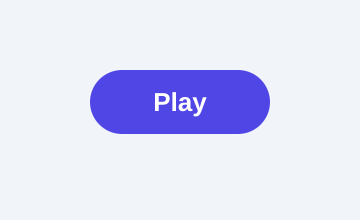

In [2]:
WIDTH, HEIGHT = 360, 220
FONT = "Arial, Helvetica, sans-serif"
doc = svg.Document(WIDTH, HEIGHT)
background = doc.rect(0, 0, WIDTH, HEIGHT, fill="#f1f5f9")
button = doc.rect(90, 70, 180, 64, rx=32, fill="#4f46e5")
label = doc.text("Play", x=WIDTH / 2, y=111, font_size=26, font_weight="bold", font_family=FONT,
                 text_anchor="middle", fill="white")
doc

Ready-made filters live in `svg.filters`. A drop shadow lifts the button off the page.

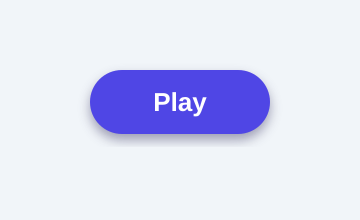

In [3]:
button.filter = svg.filters.drop_shadow(0, 6, 6, "#1e1b4b", 0.4)
doc

A glow makes the label shine.

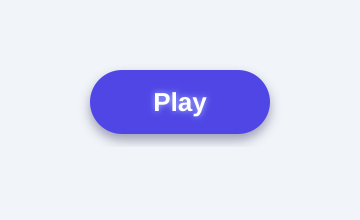

In [4]:
label.filter = svg.filters.glow(3, color="#a5b4fc")
doc

Other ready-made filters work the same way: here `long_shadow` on a badge.

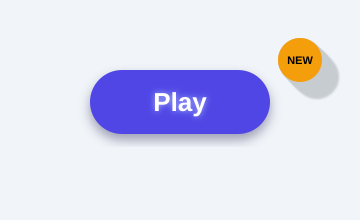

In [5]:
badge = doc.circle(300, 60, 22, fill="#f59e0b")
badge.filter = svg.filters.long_shadow()
doc.text("NEW", x=300, y=64, font_size=11, font_weight="bold", font_family=FONT, text_anchor="middle")
doc

## Building your own

A `Filter` chains small steps. Noise (`FeTurbulence`) turned grey (`FeColorMatrix`) makes a paper texture for the background.

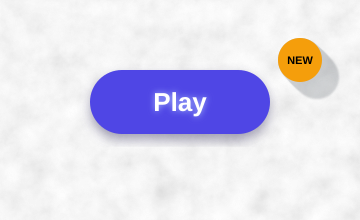

In [6]:
noise = svg.FeTurbulence(0.04, 4, seed=7, type=svg.TurbulenceType.FRACTAL_NOISE)
paper = svg.Filter(noise, svg.FeColorMatrix.saturate(0), x=0, y=0, width="100%", height="100%")
background.update(filter=paper, opacity=0.3)
doc

Blur, lighting and compositing steps make a shiny, embossed ball.

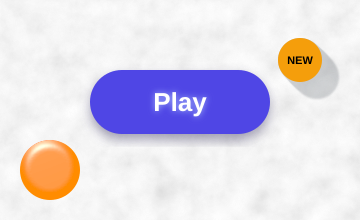

In [7]:
bump = svg.FeGaussianBlur(4, in_=svg.StandardInput.SOURCE_ALPHA)
light = svg.FeSpecularLighting(svg.FePointLight(-50, -100, 200), in_=bump, surface_scale=5,
                               specular_constant=0.8, specular_exponent=20, lighting_color="white")
shine = svg.FeComposite(svg.CompositeOperator.IN, in_=light, in2=svg.StandardInput.SOURCE_ALPHA)
lit = svg.FeComposite(svg.CompositeOperator.ARITHMETIC, in_=svg.StandardInput.SOURCE_GRAPHIC, in2=shine,
                      k1=0, k2=1, k3=1, k4=0)
doc.circle(50, 170, 30, fill="darkorange", filter=svg.Filter(bump, light, shine, lit))
doc

Save it. Next: [10 Pixels](../10_pixels/pixels.py) mixes images with shapes.

In [8]:
doc.save("09_filters.svg")